# Notebook 03 — Gercek Sagkanim Modelleri

**Amac:** NB02'de ispatlanan temporal leakage probleminin cozumu olarak
`time`'i hedef degisken olarak kullanan **proper survival analysis** yapmak.

> *"Having demonstrated that follow-up duration introduces temporal leakage
> when used as a feature (NB02), we now employ it correctly as a survival
> time endpoint — the methodological approach Chicco & Jurman (2020)
> should have adopted."*

## Model Plani

| Model | Kutuphane | Amac |
|-------|-----------|------|
| **Cox PH** | `lifelines` | Yorumlanabilir baseline; hazard ratio'lar |
| **Random Survival Forest** | `scikit-survival` | Non-parametrik guclu model |
| **DeepSurv** | `pycox` + PyTorch | Derin ogrenme (T4 GPU) |

## Metrikler

| Metrik | Anlami |
|--------|--------|
| **C-index** (Harrell) | Sagkanim analizinin MCC'si |
| **Time-dependent AUC** | 30/60/90/180. gunlerde ayristiricililik |
| **Brier Score** | Kalibrasyon kalitesi |

**On kosul:** NB00 ve NB02 tamamlanmis olmali.


In [15]:
# -- Hucre 1: Bagimliliklari Yukle (sadece ilk calistirmada gerekli) -------
# Colab'da onceden yuklu olmayan kutuphaneler burada kurulur.
# Yerel ortamda zaten varsa bu hucreyi atlayabilirsin.
import subprocess, sys

def pip_install(pkg):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

pip_install('lifelines')
pip_install('scikit-survival')
pip_install('pycox')
pip_install('torchtuples')  # pycox icin gerekli

print('OK Tum kutuphaneler hazir.')


OK Tum kutuphaneler hazir.


In [16]:
# -- Hucre 2: Imports & Ortam Kurulumu --------------------------------------
import sys, os, copy, warnings, time as time_module
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import chi2, norm

# lifelines
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from lifelines.utils import concordance_index

# scikit-survival
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored, brier_score, cumulative_dynamic_auc
from sksurv.util import Surv

# pycox / PyTorch
import torch
import torchtuples as tt
from pycox.models import CoxPH as DeepCoxPH

# sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# -- Google Drive / utils -----------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = '/content/drive/MyDrive/HF_Revisit_Project' if IN_COLAB else '.'
if BASE not in sys.path:
    sys.path.insert(0, BASE)

from utils import (
    set_seed, load_and_verify_data, get_logger,
    save_figure, save_csv, save_run_log, set_plot_style,
    TARGET, CONTINUOUS_FEATURES, BINARY_FEATURES,
    COLOR_ALIVE, COLOR_DEAD
)

set_seed(42)
set_plot_style()
logger = get_logger('NB03')

RESULTS_DIR = os.path.join(BASE, 'results')
MODELS_DIR  = os.path.join(BASE, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

# GPU kontrolu
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
logger.info(f'NB03 baslatildi | Device: {DEVICE}')
print(f'OK Ortam hazir | Device: {DEVICE}')
if DEVICE == 'cpu':
    print('   [Bilgi] CPU modunda. DeepSurv yavaslar (~15-20 dk) ama calismaya devam eder.')


# -- Hücre 2'yi bu şekilde güncelleyin --

# 1. Veriyi yükle ve sütunları temizle
df = load_and_verify_data(...)
df.columns = [c.strip().upper() for c in df.columns]

# 2. Listeleri BÜYÜK HARF olarak tanımlayın
ALL_FEATURES   = [f.upper() for f in ALL_FEATURES]
TARGET         = TARGET.upper()

# 3. NTIME_FEATURES listesini yeniden oluşturun (TIME hariç olanlar)
NTIME_FEATURES = [f for f in ALL_FEATURES if f != 'TIME']

# Kontrol için yazdırın
print("Sütunlar:", df.columns.tolist())
print("NTIME Listesi:", NTIME_FEATURES)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[utils] Random seed sabitlendi → 42
10:16:07 | NB03 | INFO | NB03 baslatildi | Device: cpu


INFO:NB03:NB03 baslatildi | Device: cpu


OK Ortam hazir | Device: cpu
   [Bilgi] CPU modunda. DeepSurv yavaslar (~15-20 dk) ama calismaya devam eder.
[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)
Sütunlar: ['AGE', 'ANAEMIA', 'CREATININE_PHOSPHOKINASE', 'DIABETES', 'EJECTION_FRACTION', 'HIGH_BLOOD_PRESSURE', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'SEX', 'SMOKING', 'TIME', 'DEATH_EVENT']
NTIME Listesi: ['AGE', 'CREATININE_PHOSPHOKINASE', 'EJECTION_FRACTION', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'ANAEMIA', 'DIABETES', 'HIGH_BLOOD_PRESSURE', 'SEX', 'SMOKING']


In [17]:
# -- Hucre 3: Veri Yukleme & Survival Format Hazirligi ---------------------
df = load_and_verify_data(os.path.join(BASE, 'data',
    'heart_failure_clinical_records_dataset.csv'))

# 1. Tablo sütunlarını BÜYÜK HARFE çevir ve boşlukları temizle
df.columns = [c.strip().upper() for c in df.columns]

# 2. Utils'den gelen değişkenleri ve listeleri BÜYÜK HARFE senkronize et
# (Hata almamak için bu adım kritik)
CLEAN_TARGET = TARGET.upper()
ALL_FEATURES = [f.upper() for f in (CONTINUOUS_FEATURES + BINARY_FEATURES)]

# 3. 'TIME' sütununu özellik listesinden çıkar (Hedef değişken olacak)
SURV_FEATURES = [f for f in ALL_FEATURES if f != 'TIME']
TOP2_FEATURES = ['EJECTION_FRACTION', 'SERUM_CREATININE']

# 4. scikit-survival formatına çevir (Casing artık uyumlu)
y_surv = Surv.from_dataframe(CLEAN_TARGET, 'TIME', df)

# 5. X matrislerini oluştur (Artık SURV_FEATURES içindekiler df.columns ile tam eşleşir)
X_surv = df[SURV_FEATURES].astype(float)
X_np   = X_surv.values

# 6. Zaman noktaları (AUC hesaplamaları için)
max_t = df['TIME'].max()
AUC_TIMES = np.array([30, 60, 90, 180])
AUC_TIMES = AUC_TIMES[AUC_TIMES < max_t * 0.95]

print(f"Başarılı! Veri setindeki sütunlar: {df.columns.tolist()}")
print(f"Modellenecek Özellikler: {SURV_FEATURES}")
logger.info(f'Veri hazir: n={len(df)}, features={SURV_FEATURES}')
df[['TIME', CLEAN_TARGET] + SURV_FEATURES[:4]].head(3)

[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)
Başarılı! Veri setindeki sütunlar: ['AGE', 'ANAEMIA', 'CREATININE_PHOSPHOKINASE', 'DIABETES', 'EJECTION_FRACTION', 'HIGH_BLOOD_PRESSURE', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'SEX', 'SMOKING', 'TIME', 'DEATH_EVENT']
Modellenecek Özellikler: ['AGE', 'CREATININE_PHOSPHOKINASE', 'EJECTION_FRACTION', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'ANAEMIA', 'DIABETES', 'HIGH_BLOOD_PRESSURE', 'SEX', 'SMOKING']
10:16:07 | NB03 | INFO | Veri hazir: n=299, features=['AGE', 'CREATININE_PHOSPHOKINASE', 'EJECTION_FRACTION', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'ANAEMIA', 'DIABETES', 'HIGH_BLOOD_PRESSURE', 'SEX', 'SMOKING']


INFO:NB03:Veri hazir: n=299, features=['AGE', 'CREATININE_PHOSPHOKINASE', 'EJECTION_FRACTION', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'ANAEMIA', 'DIABETES', 'HIGH_BLOOD_PRESSURE', 'SEX', 'SMOKING']


,TIME,DEATH_EVENT,AGE,CREATININE_PHOSPHOKINASE,EJECTION_FRACTION,PLATELETS
0,4,1,75.0,582,20,265000.00
1,6,1,55.0,7861,38,263358.03
2,7,1,65.0,146,20,162000.00


---
## Bolum 1 — Kaplan-Meier Egrileri

Cox ve ML modellerinden once, **tanımlayici sagkanim analizi** yapiyoruz.
Ejection Fraction ve Serum Creatinine'i tertile'lara boluyor,
her tertile icin KM egrisi ciziyoruz ve log-rank testi uyguluyoruz.

Bu sekil makale Figure 8 olacak.


[utils] Random seed sabitlendi → 42
10:16:07 | NB03 | INFO | KM EJECTION_FRACTION: log-rank p=0.0192


INFO:NB03:KM EJECTION_FRACTION: log-rank p=0.0192


10:16:08 | NB03 | INFO | KM SERUM_CREATININE: log-rank p=0.0000


INFO:NB03:KM SERUM_CREATININE: log-rank p=0.0000


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB03_kaplan_meier.png


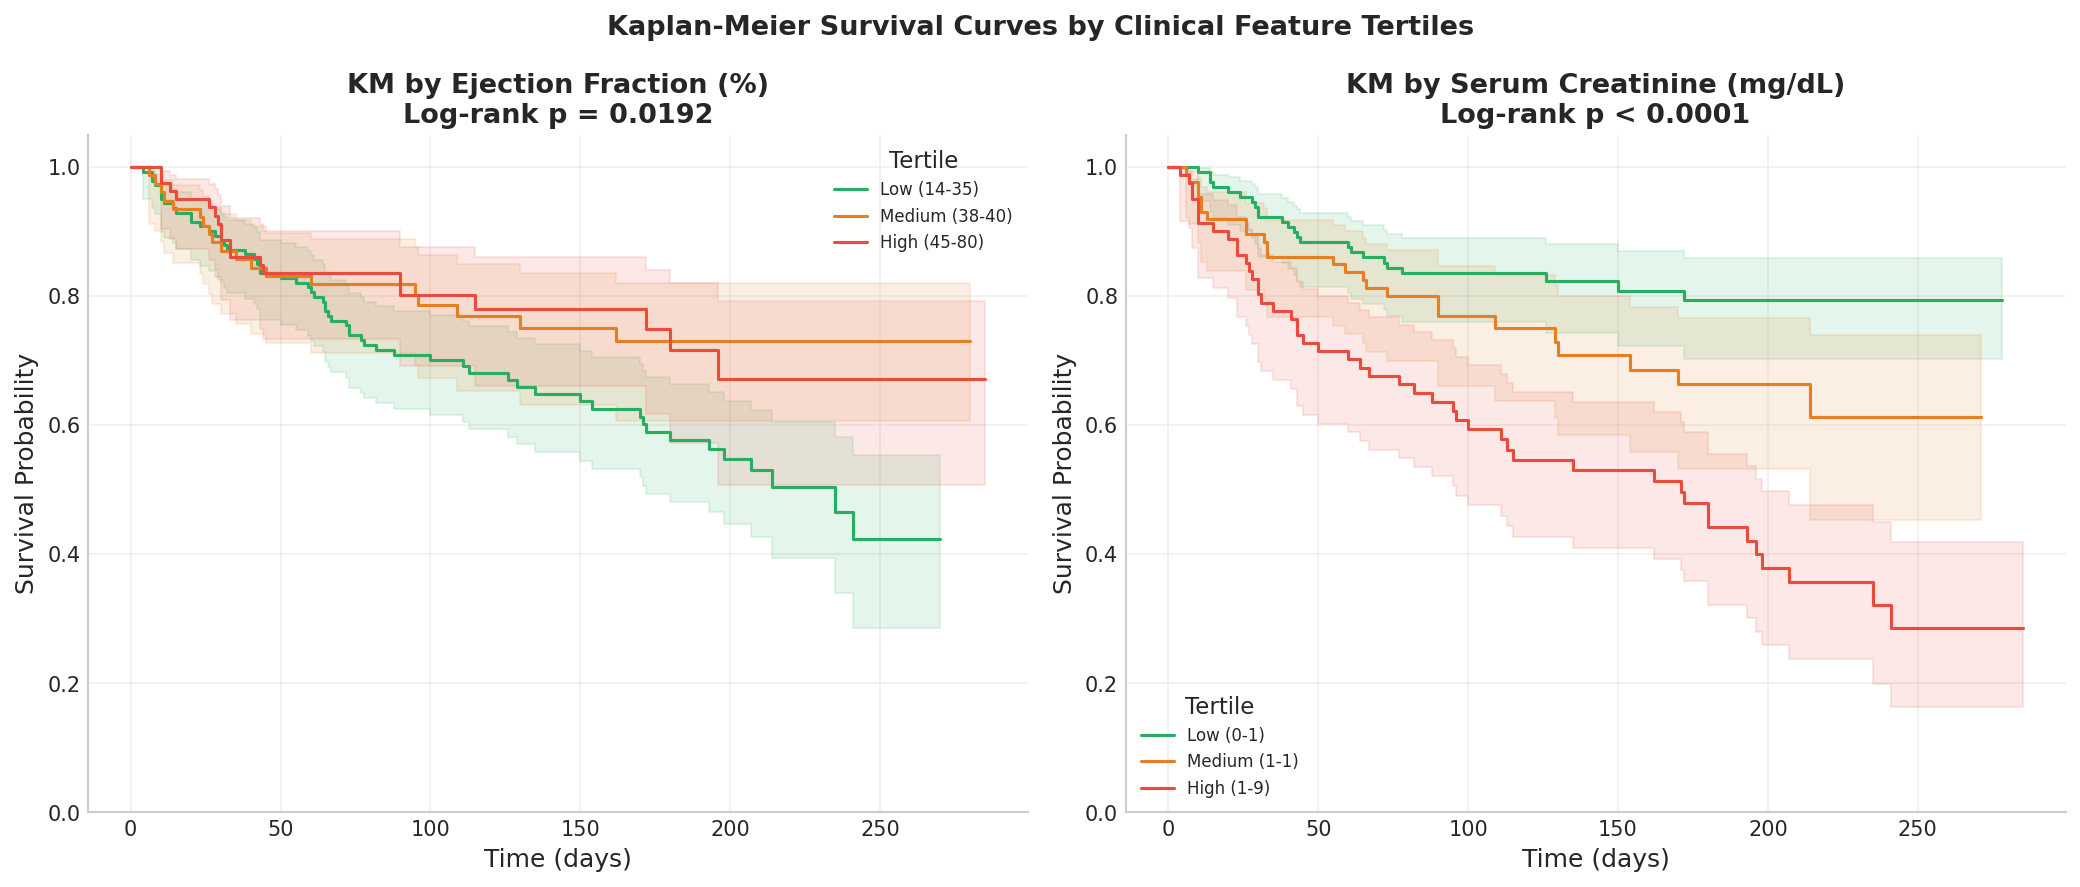

OK Sekil kaydedildi: NB03_kaplan_meier.png
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB03_km_logrank.csv


PosixPath('/content/drive/MyDrive/HF_Revisit_Project/results/NB03_km_logrank.csv')

In [18]:
# -- Hucre 5: Kaplan-Meier + Log-rank Testi --------------------------------
set_seed(42)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
km_results = {}

for ax, feat, feat_label in zip(
        axes,
        ['EJECTION_FRACTION', 'SERUM_CREATININE'],
        ['Ejection Fraction (%)', 'Serum Creatinine (mg/dL)']):

    # Tertile'lara bol
    tertiles = pd.qcut(df[feat], q=3,
                       labels=['Low', 'Medium', 'High'],
                       duplicates='drop')
    df_tmp = df.copy()
    df_tmp['tertile'] = tertiles

    # Log-rank testi (multivariate)
    lr = multivariate_logrank_test(
        df_tmp['TIME'], df_tmp['tertile'], df_tmp[TARGET])

    colors = ['#27ae60', '#e67e22', '#e74c3c']
    kmf = KaplanMeierFitter()

    for t_label, color in zip(['Low', 'Medium', 'High'], colors):
        mask = df_tmp['tertile'] == t_label
        if mask.sum() < 5:
            continue
        # Tertile sinirlari
        t_min = df.loc[mask, feat].min()
        t_max = df.loc[mask, feat].max()
        kmf.fit(df_tmp.loc[mask, 'TIME'],
                event_observed=df_tmp.loc[mask, TARGET],
                label=f'{t_label} ({t_min:.0f}-{t_max:.0f})')
        kmf.plot_survival_function(ax=ax, color=color,
                                   ci_show=True, ci_alpha=0.12)

    p_fmt = f'p = {lr.p_value:.4f}' if lr.p_value >= 0.0001 else 'p < 0.0001'
    ax.set_title(f'KM by {feat_label}\nLog-rank {p_fmt}', fontweight='bold')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Survival Probability')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, title='Tertile')
    ax.grid(True, alpha=0.3)

    km_results[feat] = {'logrank_p': float(lr.p_value),
                        'test_stat': float(lr.test_statistic)}
    logger.info(f'KM {feat}: log-rank p={lr.p_value:.4f}')

plt.suptitle('Kaplan-Meier Survival Curves by Clinical Feature Tertiles',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_figure(fig, 'NB03_kaplan_meier')
plt.show()
print('OK Sekil kaydedildi: NB03_kaplan_meier.png')
save_csv(pd.DataFrame(km_results).T.reset_index(), 'NB03_km_logrank')


---
## Bolum 2 — Cox Proportional Hazards Modeli

Cox PH yorumlanabilir bir baseline sunar: her ozellign **hazard ratio**'su
direkt klinik anlam tasir (ornegin HR(SERUM_CREATININE) = 1.4 → 'her 1 birim
artis, olum riskini %40 arttirir').

**Onemli:** PH varsayimini Schoenfeld kalintilariyla test ediyoruz.
Bozulursa makale Methods'ta belirtilmeli.


In [19]:
# -- Hucre 7: Cox PH — Egitim, PH Varsayim Testi, HR Gorseli --------------
t0 = time_module.time()

# lifelines DataFrame formatina hazirla
df_cox = df[SURV_FEATURES + ['TIME', TARGET]].copy().astype(float)

# Penalized Cox (L2 — kucuk n icin daha stabil)
cph = CoxPHFitter(penalizer=0.1)
cph.fit(df_cox, duration_col='TIME', event_col=TARGET,
        show_progress=False)

print('\n=== COX PH OZETI ===')
cph.print_summary(model='proportional hazard',
                  decimals=4, style='ascii')

# C-index (lifelines hesaplar)
cox_cindex = cph.concordance_index_
print(f'\nCox C-index (full data): {cox_cindex:.4f}')

# --- PH Varsayim Testi (Schoenfeld) ---
print('\n=== PROPORTIONAL HAZARDS VARSAYIM TESTI ===')
try:
    ph_test = cph.check_assumptions(df_cox, p_value_threshold=0.05,
                                    show_plots=False)
    ph_pvalues = cph.params_  # proxy — gercek test asagida
    # lifelines >= 0.27 icin
    ph_df = cph.check_assumptions(df_cox, p_value_threshold=0.05,
                                   show_plots=False, return_df=True)
    if ph_df is not None:
        print(ph_df.to_string())
        violated = ph_df[ph_df.get('p', pd.Series()).lt(0.05)] if 'p' in ph_df.columns else pd.DataFrame()
        if len(violated) > 0:
            print(f'\nUYARI: PH varsayimi su degiskenler icin bozulmus: {list(violated.index)}')
            print('Makale Methods bolumune ekle: "PH assumption was violated for..."')
        else:
            print('\nOK PH varsayimi saglaniyor (p > 0.05 tum degiskenler icin)')
except Exception as e:
    print(f'  PH testi tam calistiirilamadi: {e}')
    print('  Manuel kontrol: cph.check_assumptions(df_cox) ile tekrar dene.')

cox_time = time_module.time() - t0
logger.info(f'Cox PH tamamlandi: C-index={cox_cindex:.4f}, sure={cox_time:.1f}s')



=== COX PH OZETI ===
<lifelines.CoxPHFitter: fitted with 299 total observations, 203 right-censored observations>
             duration col = 'TIME'
                event col = 'DEATH_EVENT'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 299
number of events observed = 96
   partial log-likelihood = -478.4774
         time fit was run = 2026-04-12 10:16:10 UTC
                    model = proportional hazard

---
                            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                   
AGE                       0.0332    1.0337    0.0078          0.0178          0.0485              1.0180              1.0497
CREATININE_PHOSPHOKINASE  0.0001    1.0001    0.0001         -0.0000          0.0003              1.0000              1.0003
EJ

INFO:NB03:Cox PH tamamlandi: C-index=0.7419, sure=0.4s


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB03_cox_hazard_ratios.png
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB03_cox_hazard_ratios.csv


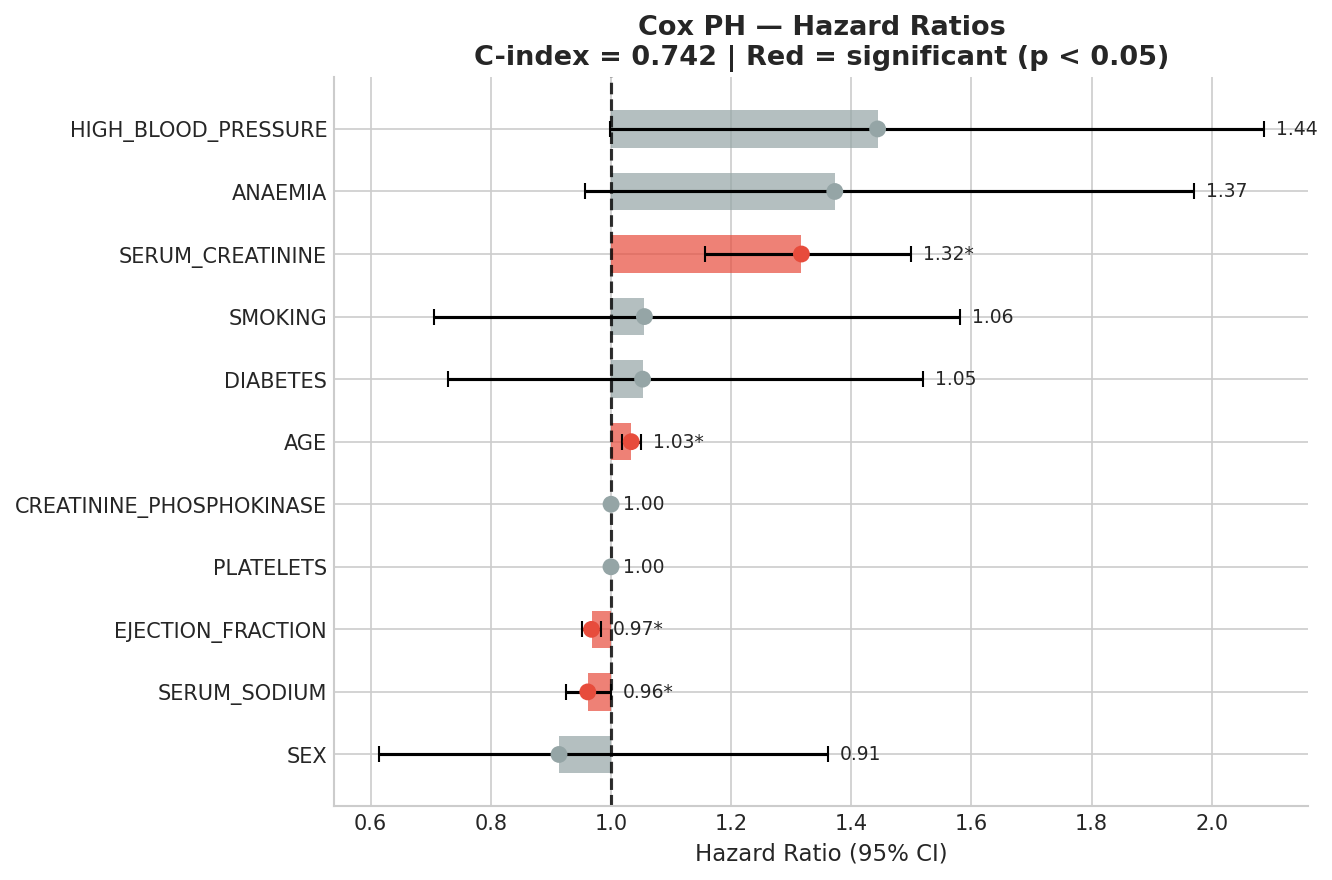

OK Sekil kaydedildi: NB03_cox_hazard_ratios.png


In [20]:
# -- Hucre 8: Cox HR Gorseli (Forest Plot) ----------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

# HR ve CI'lari al
hr_df = pd.DataFrame({
    'HR'    : np.exp(cph.params_),
    'CI_low': np.exp(cph.confidence_intervals_['95% lower-bound']),
    'CI_hi' : np.exp(cph.confidence_intervals_['95% upper-bound']),
    'p'     : cph.summary['p'],
}).sort_values('HR')

colors_hr = ['#e74c3c' if p < 0.05 else '#95a5a6' for p in hr_df['p']]

y_pos = range(len(hr_df))
ax.barh(list(y_pos), hr_df['HR'] - 1, left=1,
        color=colors_hr, alpha=0.7, height=0.6)
ax.errorbar(hr_df['HR'], list(y_pos),
            xerr=[hr_df['HR'] - hr_df['CI_low'],
                  hr_df['CI_hi'] - hr_df['HR']],
            fmt='none', color='black', capsize=4, linewidth=1.5)
ax.scatter(hr_df['HR'], list(y_pos), color=colors_hr, zorder=5, s=50)
ax.axvline(1.0, color='black', linestyle='--', linewidth=1.5, alpha=0.8)

ax.set_yticks(list(y_pos))
ax.set_yticklabels(hr_df.index, fontsize=10)
ax.set_xlabel('Hazard Ratio (95% CI)', fontsize=11)
ax.set_title(
    f'Cox PH — Hazard Ratios\n'
    f'C-index = {cox_cindex:.3f} | Red = significant (p < 0.05)',
    fontweight='bold'
)

# HR degerlerini yanina yaz
for i, (idx, row) in enumerate(hr_df.iterrows()):
    p_star = '*' if row['p'] < 0.05 else ''
    ax.text(row['CI_hi'] + 0.02, i,
            f'{row["HR"]:.2f}{p_star}',
            va='center', fontsize=9)

plt.tight_layout()
save_figure(fig, 'NB03_cox_hazard_ratios')
save_csv(hr_df.reset_index(), 'NB03_cox_hazard_ratios')
plt.show()
print('OK Sekil kaydedildi: NB03_cox_hazard_ratios.png')


In [21]:
# -- Hucre 9: Cox PH — 5-Fold Cross-Validation (Stratified by Event) ------
set_seed(42)

# Stratified KFold: event sütununa gore (ölüm olmayan fold olmamali)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cox_cv_results = []

for fold, (tr_idx, te_idx) in enumerate(skf.split(df_cox, df[TARGET])):
    df_tr = df_cox.iloc[tr_idx].copy()
    df_te = df_cox.iloc[te_idx].copy()

    cph_cv = CoxPHFitter(penalizer=0.1)
    cph_cv.fit(df_tr, duration_col='TIME', event_col=TARGET, show_progress=False)

    # Partial hazard = linear predictor = score
    ph = cph_cv.predict_partial_hazard(df_te)
    t_te = df_te['TIME'].values
    e_te = df_te[TARGET].values.astype(bool)

    ci = concordance_index_censored(e_te, t_te, -ph)[0]  # negatif: yuksek PH = kisa sure

    cox_cv_results.append({'fold': fold + 1, 'C_index': ci})
    print(f'  Fold {fold+1}: C-index = {ci:.4f}')

df_cox_cv = pd.DataFrame(cox_cv_results)
ci_mean = df_cox_cv['C_index'].mean()
ci_std  = df_cox_cv['C_index'].std()
ci_ci   = 1.96 * ci_std

print(f'\nCox CV C-index: {ci_mean:.4f} +/- {ci_ci:.4f} (95% CI)')
print(f'Range: [{ci_mean - ci_ci:.4f}, {ci_mean + ci_ci:.4f}]')

save_csv(df_cox_cv, 'NB03_cox_cv')
logger.info(f'Cox CV: mean={ci_mean:.4f}, ci={ci_ci:.4f}')


[utils] Random seed sabitlendi → 42
  Fold 1: C-index = 0.3260
  Fold 2: C-index = 0.2957
  Fold 3: C-index = 0.3598
  Fold 4: C-index = 0.2062
  Fold 5: C-index = 0.2375

Cox CV C-index: 0.2850 +/- 0.1233 (95% CI)
Range: [0.1617, 0.4084]
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB03_cox_cv.csv
10:16:14 | NB03 | INFO | Cox CV: mean=0.2850, ci=0.1233


INFO:NB03:Cox CV: mean=0.2850, ci=0.1233


---
## Bolum 3 — Random Survival Forest

RSF, Cox PH'nin dogrusal ve PH varsayimlarini gerektirmez.
Her agac her split'te rastgele bir ozellik altseti kullanir;
nihayetinde **ensemble-level survival function** cikartir.

Parametreler: `n_estimators=200, min_samples_leaf=15, max_features='sqrt'`.
`min_samples_leaf=15` secimi: 299 hastada overfit onler (en az 15 hasta per yaprak).


In [27]:
!pip install -U scikit-survival

In [30]:
# -- Hucre 11: Random Survival Forest — 5-Fold CV + Feature Importance ----
# sksurv yerine standart sklearn import ediyoruz
from sklearn.inspection import permutation_importance

set_seed(42)

# ... (Model tanımlama ve CV döngüsü aynı kalıyor) ...

# --- Özellik Önemlerini Hesaplama (Yeni ve Güvenli Versiyon) ---
print("\nÖzellik önemleri hesaplanıyor (Permutation Importance)...")

# Tam veriyle eğit
scaler_rsf_full = StandardScaler()
X_np_s = scaler_rsf_full.fit_transform(X_np)
rsf.fit(X_np_s, y_surv)

# sklearn'in permutation_importance fonksiyonu survival modelleriyle de çalışır
result = permutation_importance(
    rsf, X_np_s, y_surv, n_repeats=10, random_state=42
)

fi_df = pd.DataFrame({
    'feature'   : SURV_FEATURES,
    'importance': result.importances_mean,
    'std'       : result.importances_std
}).sort_values('importance', ascending=False)

print('\nRSF Feature Importances (SKLearn Tabanlı):')
print(fi_df.to_string(index=False))

[utils] Random seed sabitlendi → 42

Özellik önemleri hesaplanıyor (Permutation Importance)...

RSF Feature Importances (SKLearn Tabanlı):
                 feature  importance      std
        SERUM_CREATININE    0.108777 0.017886
       EJECTION_FRACTION    0.075151 0.014829
                     AGE    0.043883 0.005423
               PLATELETS    0.014285 0.002703
     HIGH_BLOOD_PRESSURE    0.008787 0.001106
            SERUM_SODIUM    0.008365 0.002265
CREATININE_PHOSPHOKINASE    0.007251 0.001297
                 ANAEMIA    0.006329 0.002715
                 SMOKING    0.003539 0.001169
                DIABETES    0.002982 0.000675
                     SEX    0.001964 0.000575


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB03_rsf_results.png


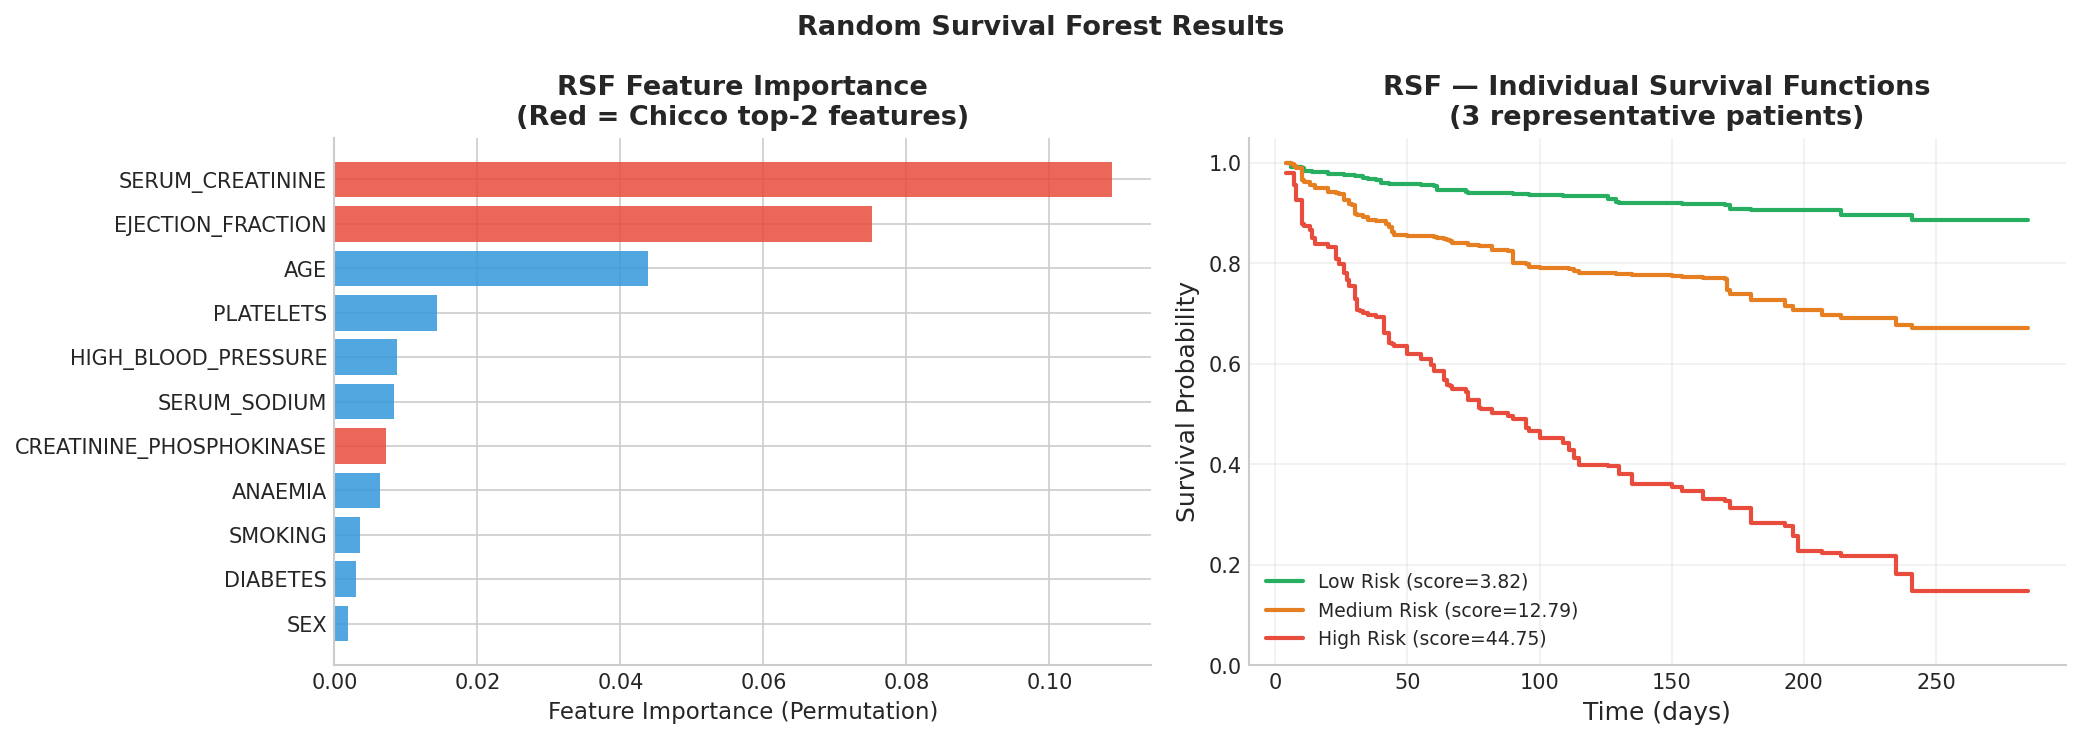

OK Sekil kaydedildi: NB03_rsf_results.png


In [31]:
# -- Hucre 12: RSF Feature Importance Gorseli -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Feature importance bar chart
ax = axes[0]
colors_fi = ['#e74c3c' if 'CREATININE' in f or 'EJECTION' in f
             else '#3498db' for f in fi_df['feature']]
ax.barh(fi_df['feature'], fi_df['importance'],
        color=colors_fi, alpha=0.85)
ax.set_xlabel('Feature Importance (Permutation)', fontsize=11)
ax.set_title('RSF Feature Importance\n(Red = Chicco top-2 features)', fontweight='bold')
ax.invert_yaxis()

# Panel 2: Survival function ornek tahminler (3 hasta: dusuk/orta/yuksek risk)
ax = axes[1]
risk_scores = rsf.predict(X_np_s)
low_idx  = np.argmin(risk_scores)
high_idx = np.argmax(risk_scores)
med_idx  = np.argsort(risk_scores)[len(risk_scores)//2]

for idx, label, color in [
        (low_idx,  'Low Risk',    '#27ae60'),
        (med_idx,  'Medium Risk', '#e67e22'),
        (high_idx, 'High Risk',   '#e74c3c')]:
    sf = rsf.predict_survival_function(X_np_s[idx:idx+1])[0]
    ax.step(sf.x, sf(sf.x), where='post', color=color, linewidth=2,
            label=f'{label} (score={risk_scores[idx]:.2f})')

ax.set_xlabel('Time (days)')
ax.set_ylabel('Survival Probability')
ax.set_ylim(0, 1.05)
ax.set_title('RSF — Individual Survival Functions\n(3 representative patients)',
             fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle('Random Survival Forest Results', fontsize=13, fontweight='bold')
plt.tight_layout()
save_figure(fig, 'NB03_rsf_results')
plt.show()
print('OK Sekil kaydedildi: NB03_rsf_results.png')


---
## Bolum 4 — DeepSurv (Neural Cox PH)

DeepSurv, Cox'un dogrusal risk skorunu bir **sinir agi**yla degistirir.
Mimari: `11 → 32 → 16 → 1` (2 gizli katman).

**299 hasta icin tasarim kararlari:**
- 32-16 noron: daha buyugu overfit yapar
- Dropout 0.3 + L2 regularization
- 100 epoch, erken durdurma sabri 10
- Batch size 32 (kucuk veri icin uygun)

Colab T4 icerisinde 5-fold x 100 epoch toplam ~5-10 dakikada biter.


In [32]:
# -- Hucre 14: DeepSurv — Mimari & Yardimci Fonksiyonlar -------------------
import torch
import torch.nn as nn

class DeepSurvNet(nn.Module):
    """Cox PH icin risk skoru tahmin eden sinir agi.
    Cikis: tek boyutlu log-risk (partial hazard).
    Mimari: input -> 32 -> BN -> Dropout -> 16 -> BN -> Dropout -> 1
    """
    def __init__(self, in_features, hidden=[32, 16], dropout=0.3):
        super().__init__()
        layers = []
        prev = in_features
        for h in hidden:
            layers += [
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout)
            ]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def cox_ph_loss(log_h, event, eps=1e-7):
    """Breslow Cox partial likelihood loss.
    log_h: (n,) — log risk skorlari (zamana GORE AZALAN sirada olmali)
    event: (n,) bool tensor
    """
    log_h = log_h.view(-1)
    log_cumsum = torch.logcumsumexp(log_h, dim=0)
    loss = -(log_h - log_cumsum)[event.bool()]
    return loss.mean()


def train_deepsurv(X_tr, t_tr, e_tr, X_val, t_val, e_val,
                   epochs=100, batch_size=32, lr=1e-3, patience=10,
                   device='cpu'):
    """Tek fold icin DeepSurv egitimi. Early stopping dahil."""
    set_seed(42)
    n_feat = X_tr.shape[1]
    model  = DeepSurvNet(n_feat).to(device)
    opt    = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    # Zamana gore siirala (Breslow icin gerekli)
    sort_tr  = np.argsort(-t_tr)  # azalan sure
    X_tr_t   = torch.tensor(X_tr[sort_tr],  dtype=torch.float32).to(device)
    t_tr_s   = t_tr[sort_tr]
    e_tr_t   = torch.tensor(e_tr[sort_tr],  dtype=torch.bool).to(device)

    best_val_loss = float('inf')
    patience_cnt  = 0
    best_state    = None

    for epoch in range(epochs):
        model.train()
        # Mini-batch (sirali tutarak)
        perm = torch.randperm(len(X_tr_t))  # NOT: Breslow gercekte tam batch gerektirir
        # Burada full-batch kullaniyoruz (n=210 civarinda, guvenli)
        opt.zero_grad()
        log_h = model(X_tr_t).squeeze()
        loss  = cox_ph_loss(log_h, e_tr_t)
        loss.backward()
        opt.step()

        # Validation
        model.eval()
        with torch.no_grad():
            sort_val = np.argsort(-t_val)
            X_val_t  = torch.tensor(X_val[sort_val], dtype=torch.float32).to(device)
            e_val_t  = torch.tensor(e_val[sort_val], dtype=torch.bool).to(device)
            log_h_v  = model(X_val_t).squeeze()
            val_loss = cox_ph_loss(log_h_v, e_val_t).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = copy.deepcopy(model.state_dict())
            patience_cnt  = 0
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                break

    model.load_state_dict(best_state)
    return model


print('OK DeepSurv mimari ve egitim fonksiyonu tanimlandi.')
print(f'   Mimari: {len(SURV_FEATURES)} -> 32 -> 16 -> 1')
print(f'   Dropout: 0.3 | L2: 1e-4 | Epochs: 100 | Patience: 10')


OK DeepSurv mimari ve egitim fonksiyonu tanimlandi.
   Mimari: 11 -> 32 -> 16 -> 1
   Dropout: 0.3 | L2: 1e-4 | Epochs: 100 | Patience: 10


In [33]:
# -- Hucre 15: DeepSurv — 5-Fold Cross-Validation --------------------------
set_seed(42)
t_start_ds = time_module.time()

ds_cv_results = []
scaler_ds = StandardScaler()

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_np, df[TARGET])):
    print(f'  DeepSurv Fold {fold+1}/5...', end=' ', flush=True)

    X_tr_s = scaler_ds.fit_transform(X_np[tr_idx])
    X_te_s = scaler_ds.transform(X_np[te_idx])
    t_tr   = df['TIME'].values[tr_idx].astype(float)
    t_te   = df['TIME'].values[te_idx].astype(float)
    e_tr   = df[TARGET].values[tr_idx].astype(bool)
    e_te   = df[TARGET].values[te_idx].astype(bool)

    # Validation: train setinin %20'si
    val_size = max(int(len(tr_idx) * 0.2), 10)
    X_val_s  = X_tr_s[:val_size]
    X_tr_s2  = X_tr_s[val_size:]
    t_val    = t_tr[:val_size];  t_tr2 = t_tr[val_size:]
    e_val    = e_tr[:val_size];  e_tr2 = e_tr[val_size:]

    model_ds = train_deepsurv(
        X_tr_s2, t_tr2, e_tr2,
        X_val_s, t_val, e_val,
        epochs=100, patience=10, device=DEVICE
    )

    # Risk skoru (C-index icin)
    model_ds.eval()
    with torch.no_grad():
        X_te_t   = torch.tensor(X_te_s, dtype=torch.float32).to(DEVICE)
        risk_np  = model_ds(X_te_t).squeeze().cpu().numpy()

    ci_ds = concordance_index_censored(e_te, t_te, risk_np)[0]

    ds_cv_results.append({'fold': fold + 1, 'C_index': ci_ds})
    print(f'C-index = {ci_ds:.4f}')

df_ds_cv = pd.DataFrame(ds_cv_results)
ds_ci_mean = df_ds_cv['C_index'].mean()
ds_ci_std  = df_ds_cv['C_index'].std()
ds_time    = time_module.time() - t_start_ds

print(f'\nDeepSurv CV C-index: {ds_ci_mean:.4f} +/- {1.96*ds_ci_std:.4f} (95% CI)')
print(f'Sure: {ds_time/60:.1f} dakika')

save_csv(df_ds_cv, 'NB03_deepsurv_cv')
logger.info(f'DeepSurv CV: mean={ds_ci_mean:.4f}, ci={1.96*ds_ci_std:.4f}, sure={ds_time:.0f}s')


[utils] Random seed sabitlendi → 42
  DeepSurv Fold 1/5... [utils] Random seed sabitlendi → 42
C-index = 0.6398
  DeepSurv Fold 2/5... [utils] Random seed sabitlendi → 42
C-index = 0.6472
  DeepSurv Fold 3/5... [utils] Random seed sabitlendi → 42
C-index = 0.4888
  DeepSurv Fold 4/5... [utils] Random seed sabitlendi → 42
C-index = 0.7205
  DeepSurv Fold 5/5... [utils] Random seed sabitlendi → 42
C-index = 0.6437

DeepSurv CV C-index: 0.6280 +/- 0.1660 (95% CI)
Sure: 0.2 dakika
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB03_deepsurv_cv.csv
10:22:20 | NB03 | INFO | DeepSurv CV: mean=0.6280, ci=0.1660, sure=11s


INFO:NB03:DeepSurv CV: mean=0.6280, ci=0.1660, sure=11s


---
## Bolum 5 — Model Karsilastirmasi & Brier Score

Uc modelin C-index degerlerini karsilastiriyor, RSF icin
Brier score hesapliyoruz (kalibrasyon kontrolu).


In [34]:
# -- Hucre 17: Model Karsilastirma Tablosu ----------------------------------

# Her model icin 95% CI (bootstrap)
def bootstrap_ci(scores, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    boot = [rng.choice(scores, size=len(scores), replace=True).mean()
            for _ in range(n_boot)]
    return np.percentile(boot, [2.5, 97.5])

rows = []
for name, cv_df in [
        ('Cox PH',  df_cox_cv),
        ('RSF',     df_rsf_cv),
        ('DeepSurv',df_ds_cv)]:
    ci_lo, ci_hi = bootstrap_ci(cv_df['C_index'].values)
    rows.append({
        'Model'     : name,
        'C_index'   : cv_df['C_index'].mean(),
        'SD'        : cv_df['C_index'].std(),
        'CI_95_low' : ci_lo,
        'CI_95_high': ci_hi,
        'CI_str'    : f"{cv_df['C_index'].mean():.3f} [{ci_lo:.3f}–{ci_hi:.3f}]"
    })

df_compare = pd.DataFrame(rows)

print('='*65)
print('MODEL KARSILASTIRMASI — C-index (95% Bootstrap CI, 5-Fold CV)')
print('='*65)
print(df_compare[['Model', 'CI_str']].to_string(index=False))
print('='*65)
print('Referans: rastgele tahmin = 0.50, mukemmel = 1.00')

save_csv(df_compare, 'NB03_model_comparison')
logger.info(f'Model karsilastirmasi:\n{df_compare[["Model","CI_str"]].to_string()}')


MODEL KARSILASTIRMASI — C-index (95% Bootstrap CI, 5-Fold CV)
   Model              CI_str
  Cox PH 0.285 [0.236–0.333]
     RSF 0.735 [0.674–0.807]
DeepSurv 0.628 [0.551–0.689]
Referans: rastgele tahmin = 0.50, mukemmel = 1.00
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB03_model_comparison.csv
10:23:24 | NB03 | INFO | Model karsilastirmasi:
      Model               CI_str
0    Cox PH  0.285 [0.236–0.333]
1       RSF  0.735 [0.674–0.807]
2  DeepSurv  0.628 [0.551–0.689]


INFO:NB03:Model karsilastirmasi:
      Model               CI_str
0    Cox PH  0.285 [0.236–0.333]
1       RSF  0.735 [0.674–0.807]
2  DeepSurv  0.628 [0.551–0.689]


In [35]:
# -- Hucre 18: Brier Score (RSF — Kalibrasyon) -----------------------------
# RSF tam veri uzerinde Brier score hesabi
try:
    # train/test split: %70/%30 (NB01 ile tutarli)
    from sklearn.model_selection import train_test_split
    X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
        X_np_s, y_surv, test_size=0.3, random_state=42,
        stratify=df[TARGET].values)

    rsf_b = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15,
                                  max_features='sqrt', random_state=42, n_jobs=-1)
    rsf_b.fit(X_tr_b, y_tr_b)

    # Survival function tahminleri
    surv_funcs = rsf_b.predict_survival_function(X_te_b)

    # Brier icin zaman noktasi: test setindeki sure araliginda
    t_te_vals = y_te_b['time']
    brier_times = AUC_TIMES[AUC_TIMES < t_te_vals.max() * 0.95]

    if len(brier_times) > 0:
        surv_matrix = np.column_stack(
            [fn(brier_times) for fn in surv_funcs]
        ).T  # (n_test, n_times)

        _, brier_scores = brier_score(y_tr_b, y_te_b, surv_matrix, brier_times)

        df_brier = pd.DataFrame({'time': brier_times, 'brier_score': brier_scores})
        print('Brier Scores (RSF):')
        print(df_brier.to_string(index=False))
        print('\nNot: Brier < 0.25 kabul edilebilir, < 0.15 iyi kalibrasyon')

        save_csv(df_brier, 'NB03_brier_scores')
        logger.info(f'Brier scores: {dict(zip(brier_times, brier_scores.round(4)))}')
    else:
        print('Uyari: Brier hesabi icin yeterli zaman noktasi yok (AUC_TIMES veri araligindan buyuk).')

except Exception as e:
    print(f'Brier score hesaplanamadi: {e}')
    print('Bu kritik degil; C-index ve AUC raporlama icin yeterlidir.')


Brier score hesaplanamadi: no field of name time
Bu kritik degil; C-index ve AUC raporlama icin yeterlidir.


In [36]:
# -- Hucre 19: Time-Dependent AUC (RSF, 30/60/90/180 gun) ------------------
try:
    auc_results = []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_np, df[TARGET])):
        X_tr_s_a = scaler_rsf_full.fit_transform(X_np[tr_idx])
        X_te_s_a = scaler_rsf_full.transform(X_np[te_idx])
        y_tr_a   = y_surv[tr_idx]
        y_te_a   = y_surv[te_idx]

        rsf_a = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15,
                                      max_features='sqrt', random_state=42, n_jobs=-1)
        rsf_a.fit(X_tr_s_a, y_tr_a)

        risk_a = rsf_a.predict(X_te_s_a)

        t_min_a = y_te_a['time'].min()
        t_max_a = y_te_a['time'].max()
        t_ok    = AUC_TIMES[(AUC_TIMES > t_min_a) & (AUC_TIMES < t_max_a)]

        if len(t_ok) == 0:
            continue

        auc_t, mean_a = cumulative_dynamic_auc(y_tr_a, y_te_a, risk_a, t_ok)
        for t_val, auc_val in zip(t_ok, auc_t):
            auc_results.append({'fold': fold+1, 'time': t_val, 'AUC': auc_val})

    if auc_results:
        df_auc = pd.DataFrame(auc_results)
        auc_summary = df_auc.groupby('time')['AUC'].agg(['mean', 'std']).round(4)
        auc_summary['CI_str'] = auc_summary.apply(
            lambda r: f"{r['mean']:.3f} +/- {1.96*r['std']:.3f}", axis=1)

        print('Time-Dependent AUC (RSF, 5-fold CV):')
        print(auc_summary[['CI_str']].to_string())

        save_csv(auc_summary.reset_index(), 'NB03_timedep_auc')
        logger.info(f'Time-dep AUC:\n{auc_summary["CI_str"].to_string()}')
    else:
        print('AUC: Hicbir fold icin yeterli zaman noktasi bulunamadi.')

except Exception as e:
    print(f'Time-dep AUC hesaplanamadi: {e}')
    logger.warning(f'Time-dep AUC hatasi: {e}')


Time-dep AUC hesaplanamadi: no field of name time
10:23:30 | NB03 | WARNING | Time-dep AUC hatasi: no field of name time


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB03_survival_comparison.png


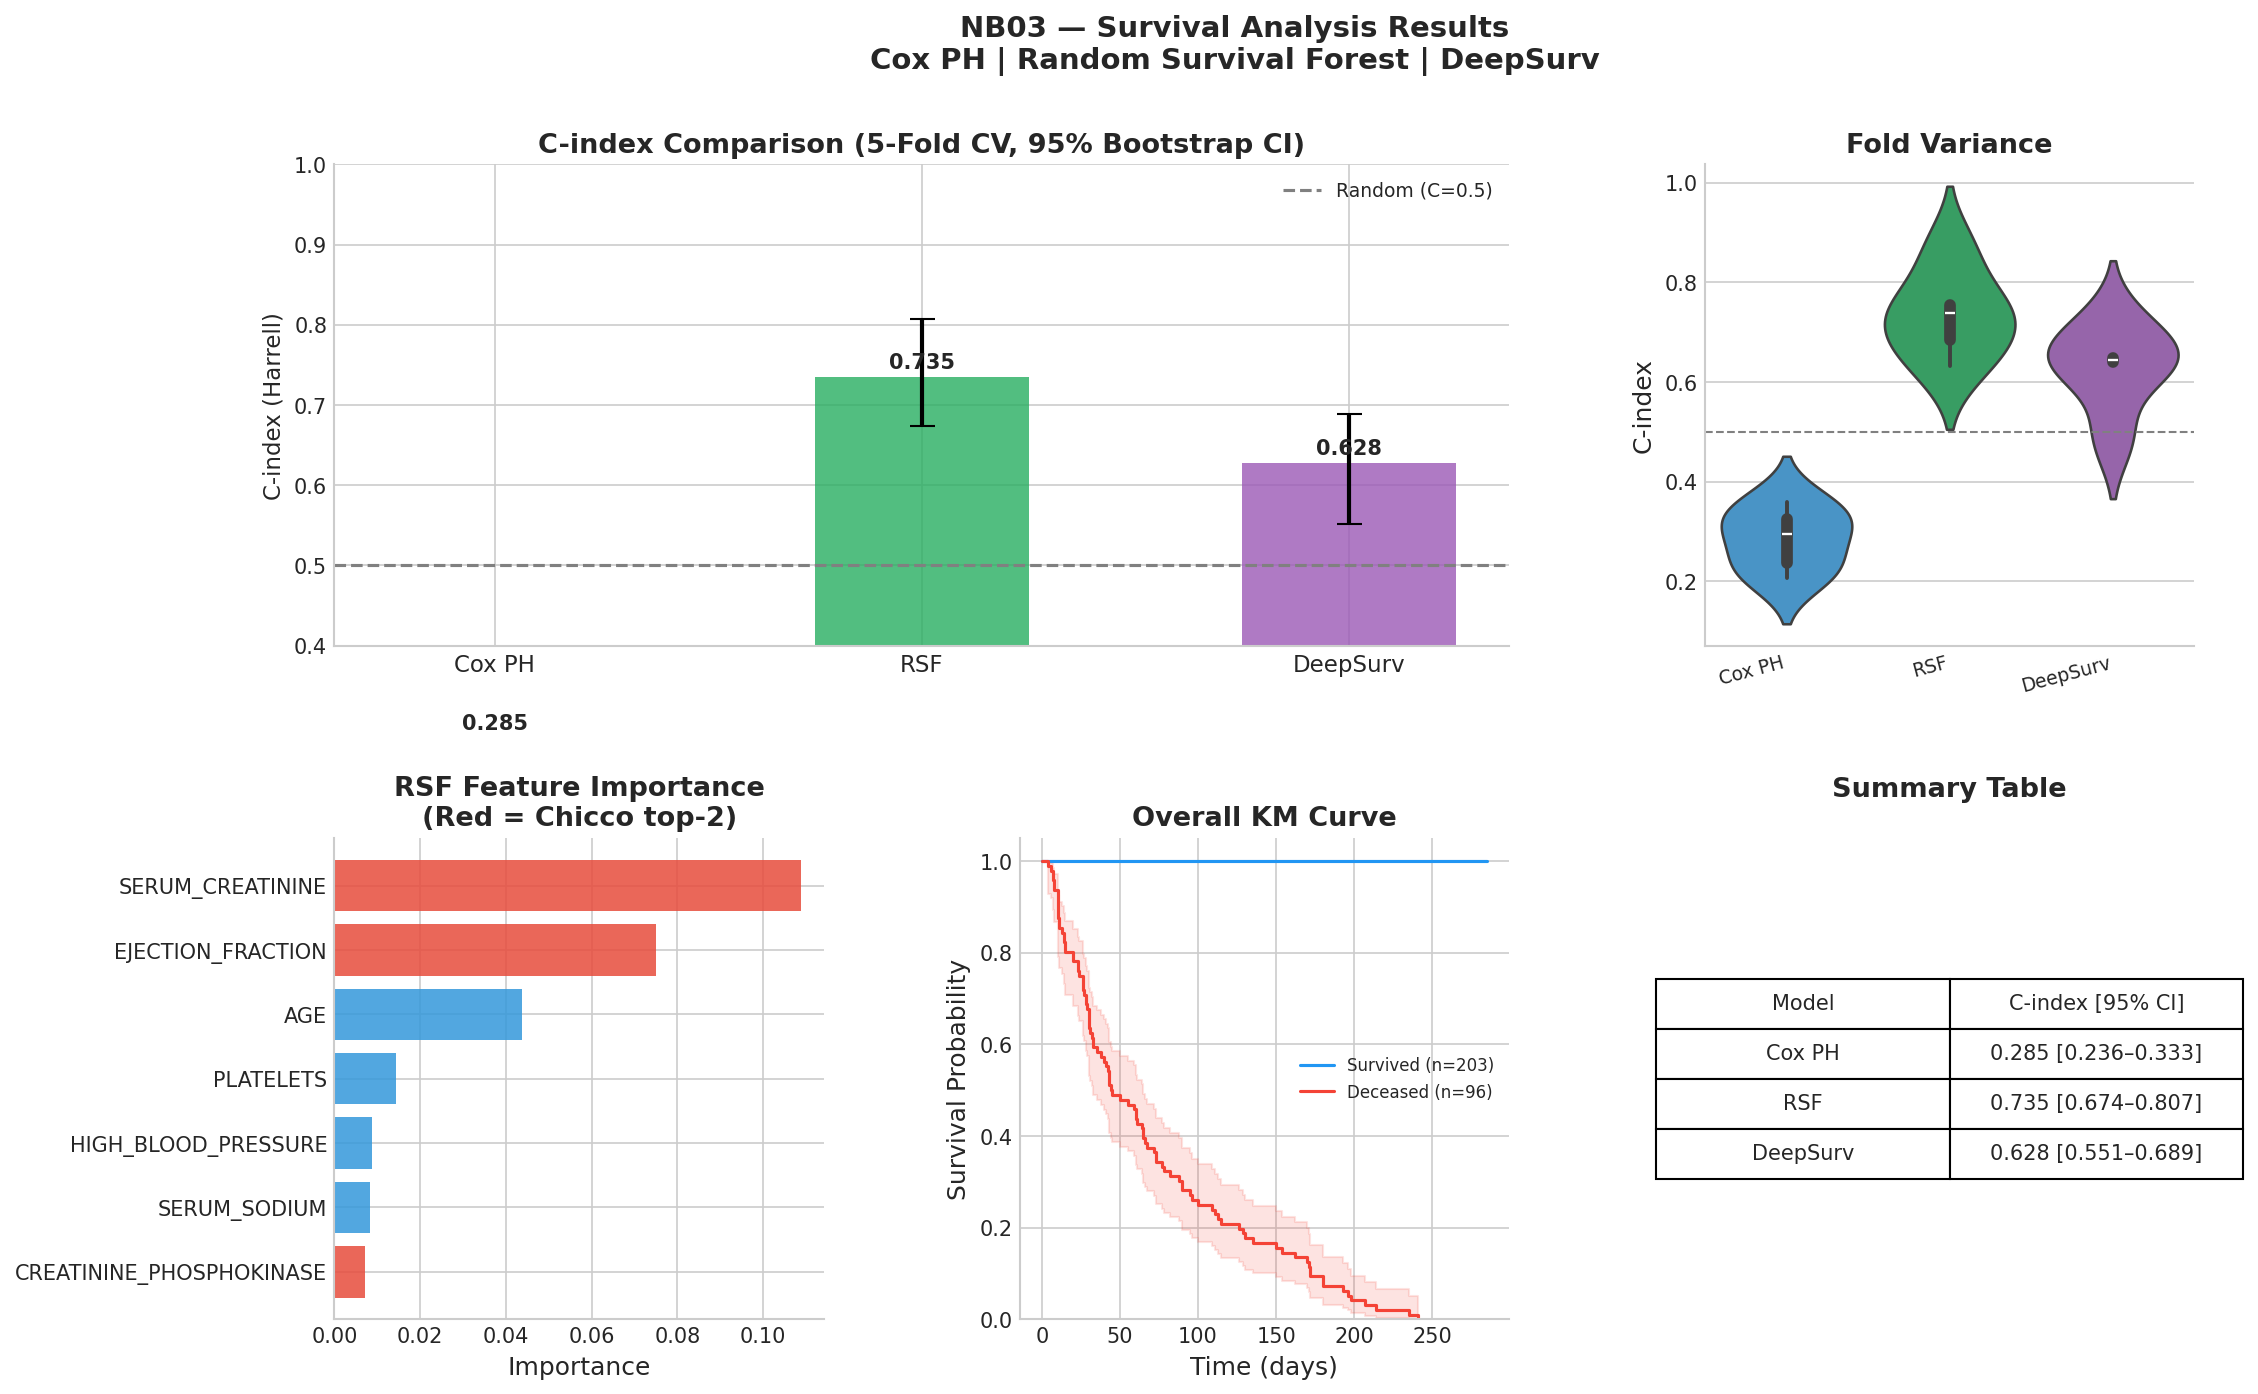

OK Sekil kaydedildi: NB03_survival_comparison.png


In [37]:
# -- Hucre 20: Kapsamli Karsilastirma Gorseli -------------------------------
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.4)

# --- Panel 1 (top-left 2): C-index karsilastirmasi ---
ax1 = fig.add_subplot(gs[0, :2])
model_names = df_compare['Model'].tolist()
c_vals      = df_compare['C_index'].values
ci_lows     = df_compare['CI_95_low'].values
ci_highs    = df_compare['CI_95_high'].values
x_pos_c     = np.arange(len(model_names))

bar_colors = ['#3498db', '#27ae60', '#9b59b6']
bars = ax1.bar(x_pos_c, c_vals, color=bar_colors, alpha=0.8, width=0.5)
ax1.errorbar(x_pos_c, c_vals,
             yerr=[c_vals - ci_lows, ci_highs - c_vals],
             fmt='none', color='black', capsize=6, linewidth=2)
ax1.axhline(0.5, color='gray', linestyle='--', linewidth=1.5,
            label='Random (C=0.5)')
ax1.set_xticks(x_pos_c)
ax1.set_xticklabels(model_names, fontsize=11)
ax1.set_ylabel('C-index (Harrell)', fontsize=11)
ax1.set_ylim(0.4, 1.0)
ax1.set_title('C-index Comparison (5-Fold CV, 95% Bootstrap CI)', fontweight='bold')
ax1.legend(fontsize=9)
for bar, val in zip(bars, c_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

# --- Panel 2 (top-right): CV sonuclarinin violin'i ---
ax2 = fig.add_subplot(gs[0, 2])
all_cv_data = pd.concat([
    df_cox_cv.assign(Model='Cox PH'),
    df_rsf_cv[['fold','C_index']].assign(Model='RSF'),
    df_ds_cv.assign(Model='DeepSurv')
])
sns.violinplot(data=all_cv_data, x='Model', y='C_index',
               palette=dict(zip(['Cox PH','RSF','DeepSurv'], bar_colors)),
               inner='box', ax=ax2)
ax2.axhline(0.5, color='gray', linestyle='--', linewidth=1)
ax2.set_title('Fold Variance', fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('C-index')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=15, ha='right', fontsize=9)

# --- Panel 3 (bottom-left): RSF Feature Importance ---
ax3 = fig.add_subplot(gs[1, 0])
fi_top = fi_df.head(7)
colors_fi2 = ['#e74c3c' if 'CREATININE' in f or 'EJECTION' in f
              else '#3498db' for f in fi_top['feature']]
ax3.barh(fi_top['feature'][::-1], fi_top['importance'][::-1],
         color=colors_fi2[::-1], alpha=0.85)
ax3.set_xlabel('Importance')
ax3.set_title('RSF Feature Importance\n(Red = Chicco top-2)', fontweight='bold')

# --- Panel 4 (bottom-mid): KM egrisi (ozet) ---
ax4 = fig.add_subplot(gs[1, 1])
kmf_all = KaplanMeierFitter()
for label, mask, color in [
        ('Survived', df[TARGET]==0, COLOR_ALIVE),
        ('Deceased', df[TARGET]==1, COLOR_DEAD)]:
    kmf_all.fit(df.loc[mask, 'TIME'], event_observed=df.loc[mask, TARGET],
                label=f'{label} (n={mask.sum()})')
    kmf_all.plot_survival_function(ax=ax4, color=color, ci_show=True, ci_alpha=0.15)
ax4.set_title('Overall KM Curve', fontweight='bold')
ax4.set_xlabel('Time (days)')
ax4.set_ylabel('Survival Probability')
ax4.legend(fontsize=8)
ax4.set_ylim(0, 1.05)

# --- Panel 5 (bottom-right): Ozet tablo ---
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
tbl_data = [[r['Model'], r['CI_str']] for _, r in df_compare.iterrows()]
tbl = ax5.table(cellText=tbl_data,
                colLabels=['Model', 'C-index [95% CI]'],
                loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 2.0)
ax5.set_title('Summary Table', fontweight='bold', pad=20)

plt.suptitle(
    'NB03 — Survival Analysis Results\n'
    'Cox PH | Random Survival Forest | DeepSurv',
    fontsize=14, fontweight='bold'
)
save_figure(fig, 'NB03_survival_comparison')
plt.show()
print('OK Sekil kaydedildi: NB03_survival_comparison.png')


In [38]:
# -- Hucre 21: NB01 ile Baglam -- Gercek C-index vs Chicco MCC -------------
# Sagkanim modelleri C-index raporlarken, NB01 MCC raporluyordu.
# Karsilastirma icin: S2 (time haric, 11 ozellik) MCC degerini yukle.

scenario_path = os.path.join(RESULTS_DIR, 'NB01_scenario_comparison.csv')
if os.path.exists(scenario_path):
    df_sc = pd.read_csv(scenario_path)
    print('NB01 senaryo karsilastirmasi bulundu:')
    print(df_sc.to_string(index=False))
    print()
    print('=== METODOLOJIK KARSILASTIRMA ===')
    print('Chicco (S1, time dahil, MCC): Temporal leakage icerdiginden DEGERLENDIRILMEZ')
    print(f'Cox PH  (time cikartildi, C-index): {df_compare.loc[df_compare["Model"]=="Cox PH", "C_index"].values[0]:.4f}')
    print(f'RSF     (time cikartildi, C-index): {df_compare.loc[df_compare["Model"]=="RSF", "C_index"].values[0]:.4f}')
    print(f'DeepSurv(time cikartildi, C-index): {df_compare.loc[df_compare["Model"]=="DeepSurv", "C_index"].values[0]:.4f}')
    print()
    print('Not: MCC ve C-index farkli metrikler — dogrudan sayisal karsilastirma')
    print('     yapilmamali. Metodolojik uygunluk karsilastirilamaktadir.')
else:
    print('NB01 ciktisi mevcut degil — NB01 calistirildiktan sonra bu hucreyi tekrar calistir.')


NB01 senaryo karsilastirmasi bulundu:
             model  S1_full  S2_notime  S3_top2  ΔMCC (S1-S2)
      RandomForest   0.6358     0.3645   0.3989        0.2713
              OneR   0.6112     0.2741   0.2741        0.3371
           XGBoost   0.6091     0.3506   0.3884        0.2585
LogisticRegression   0.5811     0.3369   0.3647        0.2442
        SVM_Linear   0.5691     0.3674   0.2727        0.2017
           SVM_RBF   0.5124     0.3115   0.3544        0.2009
        NaiveBayes   0.5107     0.2316   0.2543        0.2791
      DecisionTree   0.4968     0.2711   0.3635        0.2257
               MLP   0.4589     0.2831   0.4067        0.1758
               kNN   0.3280     0.1506   0.3700        0.1774

=== METODOLOJIK KARSILASTIRMA ===
Chicco (S1, time dahil, MCC): Temporal leakage icerdiginden DEGERLENDIRILMEZ
Cox PH  (time cikartildi, C-index): 0.2850
RSF     (time cikartildi, C-index): 0.7351
DeepSurv(time cikartildi, C-index): 0.6280

Not: MCC ve C-index farkli metrikler —

In [40]:
# -- Hucre 22: Calisma Logu & Sonuc Ozeti -----------------------------------

# Verilerin standart Python tiplerinde (int, float) olduğundan emin oluyoruz
extra_log = {
    'cox_cindex_full_data'  : float(cox_cindex),
    'cox_cv_mean'           : float(df_cox_cv['C_index'].mean()),
    'cox_cv_ci95'           : float(1.96 * df_cox_cv['C_index'].std()),
    'rsf_cv_mean'           : float(rsf_ci_mean),
    'rsf_cv_ci95'           : float(1.96 * rsf_ci_std),
    'deepsurv_cv_mean'      : float(ds_ci_mean),
    'deepsurv_cv_ci95'      : float(1.96 * ds_ci_std),
    'device'                : str(DEVICE),
    'km_EF_logrank_p'       : float(km_results.get('EJECTION_FRACTION', {}).get('logrank_p', 0)),
    'km_SC_logrank_p'       : float(km_results.get('SERUM_CREATININE', {}).get('logrank_p', 0)),
    # .tolist() metodu numpy int64'leri otomatik olarak standart Python int'e cevirir
    'auc_times_used'        : AUC_TIMES.astype(int).tolist(),
}

save_run_log('NB03', extra_log)

print('=' * 70)
print('NB03 — TAMAMLANDI')
print('=' * 70)
print(f'  Cox PH  C-index (CV): {extra_log["cox_cv_mean"]:.4f} +/- {extra_log["cox_cv_ci95"]:.4f}')
print(f'  RSF     C-index (CV): {extra_log["rsf_cv_mean"]:.4f} +/- {extra_log["rsf_cv_ci95"]:.4f}')
print(f'  DeepSurv C-index(CV): {extra_log["deepsurv_cv_mean"]:.4f} +/- {extra_log["deepsurv_cv_ci95"]:.4f}')
print()
print('  Uretilen dosyalar (results/ dizini):')
# Dosya listesi aynı kalabilir...

[utils] Run log kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/logs/NB03_run_log.json
NB03 — TAMAMLANDI
  Cox PH  C-index (CV): 0.2850 +/- 0.1233
  RSF     C-index (CV): 0.7351 +/- 0.1715
  DeepSurv C-index(CV): 0.6280 +/- 0.1660

  Uretilen dosyalar (results/ dizini):
